<img src="https://www.unad.edu.co/images/footer/logo-unad-acreditacion-min.png" width="780" height="140" align="right"/>

<p style="text-align: center;"> Course: Natural Language Processing</p>

<p style="text-align: center;"> Group: 02 </p>

<p style="text-align: center;"> Phase 3 - Sentiment Analysis and Information Retrieval</p>

<p style="text-align: center;">  Presented by: Jeronimo Ramos Ruiz </p>

<p style="text-align: center;">  Tutor: ANDRES FELIPE HERNANDEZ GIRALDO</p>

<p style="text-align: center;"> UNIVERSIDAD NACIONAL ABIERTA Y A DISTANCIA - UNAD </p>

<p style="text-align: center;"> Medellín, October 2026</p>

---

# Information Retrieval on the CISI Collection — Ranking Models, Preprocessing and Representations

This notebook designs and evaluates an information-retrieval (IR) system on **CISI** (1,460 library-science abstracts, 112 natural-language queries,
and relevance judgments).

| Part | Content |
|---|---|
| **1** | Loading `CISI.ALL`, `CISI.QRY`, `CISI.REL` (and, optionally, `CISI.BLN`); collection statistics |
| **2** | Preprocessing of documents *and* queries: four variants (raw / clean / stemmed / lemmatized) |
| **3** | Evaluation framework: P, R, F1 @ 5/10/20, MAP, nDCG@10, MRR, interpolated P–R curves; sanity checks |
| **4** | Retrieval models: TF-IDF + cosine, BM25, LSA, Word2Vec, GloVe, (optional) sentence-transformers, hybrid fusion |
| **5** | Experiments: preprocessing study, model/representation comparison, query-level cross-validated tuning, significance tests, per-query analysis |
| **6** | Natural-language search engine demo (free-text queries mapped to the same space as the documents) |
| **7** | Boolean retrieval baseline (`CISI.BLN`) |
| **8** | Consolidated comparison, discussion and conclusions |

**Design principles.** (i) The *same* function maps a query text to scores for both the evaluation queries and any free-text query typed by a user, so the evaluation
reflects the real search path. (ii) Only the 76 queries that have relevance judgments are evaluated. (iii) Hyper-parameters are tuned with **cross-validation over queries**
(Section 5.3), never on the queries used to report the final number without disclosure. (iv) Every number is accompanied by uncertainty (bootstrap CI / paired tests), because
76 queries is a small sample.

## 0. Setup and configuration

In [1]:
# pip install numpy pandas scipy scikit-learn matplotlib nltk gensim   (optional: sentence-transformers)
import os, re, time, math, pickle, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy import stats
from IPython.display import display

from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.model_selection import RepeatedKFold

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk import pos_tag

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    try: nltk.download(pkg, quiet=True)
    except Exception as e: print("could not download", pkg, e)

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.RandomState(SEED)

# ---------------- configuration ----------------
DATA_DIR = "."                                   # folder with CISI.ALL, CISI.QRY, CISI.REL (and optionally CISI.BLN)
GLOVE_MODELS = ["glove-wiki-gigaword-100", "glove-wiki-gigaword-300"]   # pretrained GloVe (gensim downloader)
USE_SBERT = True                                  # tries a sentence-transformer; silently skipped if unavailable
SBERT_MODEL = "all-MiniLM-L6-v2"
KS = (5, 10, 20)                                  # cut-offs for precision / recall / F1
CACHE_FILE = "cisi_tokens_cache.pkl"              # preprocessing cache (delete it to recompute)

# 1. Loading the collection

* **`CISI.ALL`** — documents in a field-tagged format: `.I` id, `.T` title, `.A` author, `.W` abstract, `.X` cross-references (ignored).
* **`CISI.QRY`** — the 112 queries (`.I` id, `.W` natural-language text).
* **`CISI.REL`** — relevance judgments: one line per relevant (query, document) pair (binary relevance; the remaining columns are unused placeholders).
* **`CISI.BLN`** — Boolean query formulations (used only in Section 7, if the file is present).

A document is indexed as **title + abstract** (the title is short but very informative); Section 5.1 includes an ablation with the abstract only.

In [2]:
def parse_tagged(path):
    '''Parse a CISI-style field-tagged file into a list of dicts {id, T, A, W}.
    A tag is a line starting with ".I/.T/.A/.W/.X/.B"; field content may span several lines. ".X" blocks are skipped.'''
    tag_re = re.compile(r"^\.(I|T|A|W|X|B)\b\s?(.*)$")
    with open(path, encoding="utf-8", errors="replace") as f:
        lines = f.read().replace("\r\n", "\n").split("\n")
    recs, cur, field = [], None, None
    for line in lines:
        m = tag_re.match(line)
        if m:
            tag, rest = m.groups()
            if tag == "I":
                if cur is not None: recs.append(cur)
                cur = {"id": int(rest.strip()), "T": "", "A": "", "W": ""}; field = None
            elif tag in ("X", "B"):
                field = None
            else:
                field = tag
                if rest.strip(): cur[tag] += rest + " "
        elif cur is not None and field in ("T", "A", "W"):
            cur[field] += line + " "
    if cur is not None: recs.append(cur)
    for r in recs:
        for k in ("T", "A", "W"): r[k] = re.sub(r"\s+", " ", r[k]).strip()
    return recs

docs = pd.DataFrame(parse_tagged(f"{DATA_DIR}/CISI.ALL")).rename(columns={"id": "doc_id", "T": "title", "A": "author", "W": "abstract"})
queries = pd.DataFrame(parse_tagged(f"{DATA_DIR}/CISI.QRY")).rename(columns={"id": "qid", "W": "text"})[["qid", "text"]]

rel_pairs = []
with open(f"{DATA_DIR}/CISI.REL", encoding="utf-8", errors="replace") as f:
    for line in f:
        p = line.split()
        if len(p) >= 2: rel_pairs.append((int(p[0]), int(p[1])))
rel_df = pd.DataFrame(rel_pairs, columns=["qid", "doc_id"]).drop_duplicates()

# consistency checks between the three files
assert docs.doc_id.is_unique and queries.qid.is_unique
print("documents:", len(docs), "| queries:", len(queries), "| judgments (unique pairs):", len(rel_df))
print("REL doc ids not in collection:", (~rel_df.doc_id.isin(docs.doc_id)).sum(), "| REL query ids not in QRY:", (~rel_df.qid.isin(queries.qid)).sum())

D_IDS = docs.doc_id.values; D = len(D_IDS); doc_pos = {d: i for i, d in enumerate(D_IDS)}
Q_IDS = queries.qid.values; QUERY_TEXTS = queries.text.tolist()
EVAL_QIDS = np.array(sorted(rel_df.qid.unique()))            # only these queries can be evaluated
EVAL_ROWS = np.array([int(np.where(Q_IDS == q)[0][0]) for q in EVAL_QIDS])
REL = np.zeros((len(EVAL_QIDS), D), dtype=np.int8)
for qi, q in enumerate(EVAL_QIDS):
    for d in rel_df.loc[rel_df.qid == q, "doc_id"]: REL[qi, doc_pos[d]] = 1
N_REL = REL.sum(1)

print(f"queries with judgments: {len(EVAL_QIDS)} of {len(Q_IDS)} (the other {len(Q_IDS) - len(EVAL_QIDS)} cannot be evaluated)")
print("relevant documents per evaluated query:"); display(pd.Series(N_REL).describe().round(1).to_frame().T)
print("docs with empty abstract:", (docs.abstract == "").sum(), "| mean abstract length (words): %.0f" % docs.abstract.str.split().str.len().mean())
print("mean query length (words): %.1f" % queries.text.str.split().str.len().mean())
docs.head(3).assign(abstract=lambda d: d.abstract.str.slice(0, 80) + "…")

documents: 1460 | queries: 112 | judgments (unique pairs): 3114
REL doc ids not in collection: 0 | REL query ids not in QRY: 0
queries with judgments: 76 of 112 (the other 36 cannot be evaluated)
relevant documents per evaluated query:


,count,mean,std,min,25%,50%,75%,max
0,76.0,41.0,36.2,1.0,13.0,30.5,52.2,155.0


docs with empty abstract: 0 | mean abstract length (words): 119
mean query length (words): 75.9


,doc_id,title,author,abstract
0,1,18 Editions of the Dewey Decimal Classifications,"Comaromi, J.P.",The present study is a history of the DEWEY De...
1,2,Use Made of Technical Libraries,"Slater, M.",This report is an analysis of 6300 acts of use...
2,3,Two Kinds of Power An Essay on Bibliographic C...,"Wilson, P.",The relationships between the organization and...


In [3]:
DOC_TEXT = (docs.title + ". " + docs.abstract).tolist()      # what is indexed: title + abstract
print("Example query:", QUERY_TEXTS[43][:230], "…")
print("Relevant docs for it:", int(N_REL[list(EVAL_QIDS).index(44)]) if 44 in EVAL_QIDS else "-")

Example query: There are presently fifty to one hundred technical journals being published. On the average, two new journals appear every day. In the many journals published, one to two million articles appear every year. What attempts have been …
Relevant docs for it: 155


# 2. Preprocessing of documents and queries

Documents and queries go through **exactly the same** function. One base pass tokenizes (lowercase, hyphens/slashes split, NLTK `word_tokenize`, punctuation stripped inside tokens);
four **variants** are then derived so their effect can be compared:

| Variant | Operations |
|---|---|
| `raw` | lowercase + tokenization only (keeps stop-words and numbers) |
| `clean` | `raw` − stop-words (NLTK English) − pure numbers − 1-character tokens |
| `stem` | `clean` + Porter stemming |
| `lemma` | `clean` + POS-aware WordNet lemmatization (real words, required to look words up in GloVe) |

Numbers are dropped from `clean/stem/lemma` because bare numbers (years, page counts) are rarely discriminative in this collection; alphanumeric tokens are kept.

In [4]:
STOP = set(stopwords.words("english"))
porter, lemmatizer = PorterStemmer(), WordNetLemmatizer()
VARIANTS = ["raw", "clean", "stem", "lemma"]

def _wn_pos(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)

def base_tokens(text):
    '''Lowercase, split hyphens/slashes, tokenize, strip non-alphanumerics from each token, drop empties.'''
    text = re.sub(r"[-/]", " ", text.lower())
    toks = [re.sub(r"[^a-z0-9]", "", t) for t in word_tokenize(text)]
    return [t for t in toks if t]

def preprocess_variants(text, want_lemma=True):
    '''Return {raw, clean, stem, lemma} token lists for one text (cached on disk, see below).'''
    raw = base_tokens(text)
    clean = [t for t in raw if t not in STOP and not t.isdigit() and len(t) > 1]
    out = {"raw": raw, "clean": clean, "stem": [porter.stem(t) for t in clean]}
    if want_lemma:
        out["lemma"] = [lemmatizer.lemmatize(t, _wn_pos(tag)) for t, tag in pos_tag(clean)] if clean else []
    return out

_CACHE = pickle.load(open(CACHE_FILE, "rb")) if os.path.exists(CACHE_FILE) else {}
def cached_variants(text, want_lemma=True):
    key = (text, want_lemma)
    if key not in _CACHE: _CACHE[key] = preprocess_variants(text, want_lemma)
    return _CACHE[key]

t0 = time.time()
DOC_VARS = [cached_variants(t) for t in DOC_TEXT]
Q_VARS = [cached_variants(t) for t in QUERY_TEXTS]
pickle.dump(_CACHE, open(CACHE_FILE, "wb"))
DOC_TOK = {v: [d[v] for d in DOC_VARS] for v in VARIANTS}
Q_TOK = {v: [d[v] for d in Q_VARS] for v in VARIANTS}
print(f"preprocessing done in {time.time() - t0:.0f}s")

vt = pd.DataFrame({v: {"vocabulary": len(set(t for d in DOC_TOK[v] for t in d)),
                       "tokens / doc": np.mean([len(d) for d in DOC_TOK[v]]),
                       "tokens / query": np.mean([len(q) for q in Q_TOK[v]])} for v in VARIANTS}).T.round(1)
display(vt)
i = 0
print("\nExample query 1 ->")
for v in VARIANTS: print(f"  {v:>5}: {Q_TOK[v][i][:14]}")

preprocessing done in 0s


,vocabulary,tokens / doc,tokens / query
raw,10111.0,128.3,76.5
clean,9543.0,71.0,43.7
stem,5718.0,71.0,43.7
lemma,7649.0,71.0,43.7



Example query 1 ->
    raw: ['what', 'problems', 'and', 'concerns', 'are', 'there', 'in', 'making', 'up', 'descriptive', 'titles', 'what', 'difficulties', 'are']
  clean: ['problems', 'concerns', 'making', 'descriptive', 'titles', 'difficulties', 'involved', 'automatically', 'retrieving', 'articles', 'approximate', 'titles', 'usual', 'relevance']
   stem: ['problem', 'concern', 'make', 'descript', 'titl', 'difficulti', 'involv', 'automat', 'retriev', 'articl', 'approxim', 'titl', 'usual', 'relev']
  lemma: ['problem', 'concern', 'make', 'descriptive', 'title', 'difficulty', 'involve', 'automatically', 'retrieve', 'article', 'approximate', 'title', 'usual', 'relevance']


# 3. Evaluation framework

For each evaluated query the system returns a score for **every** document; documents are ranked by decreasing score (ties broken by document order, deterministic).
With binary relevance and `n_rel` relevant documents:

* **Precision@k** = TP@k / k  **Recall@k** = TP@k / n_rel  **F1@k** = harmonic mean of the two.
  (Recall@k cannot reach 1 when `n_rel > k`; several CISI queries have > 100 relevant documents, so absolute P/R/F1@k values are bounded and must be read relative to each other.)
* **AP** (average precision) = mean of the precision at the rank of each relevant document; **MAP** = mean AP over queries — the main summary metric.
* **nDCG@10** with binary gains, discount 1/log2(rank+1). **MRR** = mean reciprocal rank of the first relevant document.
* **Interpolated P–R curve**: precision at recall levels 0.0 … 1.0, averaged over queries.

Sanity checks: an **oracle** (scores = relevance) must give MAP = 1; a **random** ranking gives the chance level.

In [5]:
def rank_matrix(S):
    '''Binary relevance of the documents in ranked order for every evaluated query (S: n_eval x D scores).'''
    order = np.argsort(-S, axis=1, kind="stable")
    return np.take_along_axis(REL, order, axis=1)

def per_query_metrics(S):
    '''Metrics for each evaluated query. S has shape (n_eval, D). Returns a DataFrame indexed by query id.'''
    rel = rank_matrix(S); cum = np.cumsum(rel, axis=1); ranks = np.arange(1, D + 1)
    out = {}
    for k in KS:
        tp = cum[:, k - 1]; p = tp / k; r = tp / N_REL
        out[f"P@{k}"], out[f"R@{k}"] = p, r
        out[f"F1@{k}"] = np.where(tp > 0, 2 * p * r / np.maximum(p + r, 1e-12), 0.0)
    out["AP"] = ((cum / ranks) * rel).sum(1) / N_REL
    disc = 1 / np.log2(np.arange(2, 12))
    out["nDCG@10"] = (rel[:, :10] * disc).sum(1) / np.array([disc[:min(n, 10)].sum() for n in N_REL])
    out["RR"] = 1 / ((rel > 0).argmax(1) + 1)
    return pd.DataFrame(out, index=EVAL_QIDS)

def summarize(pq):
    '''Mean over queries; AP -> MAP and RR -> MRR.'''
    return pq.mean().rename({"AP": "MAP", "RR": "MRR"})

def interpolated_pr(S, levels=np.linspace(0, 1, 11)):
    rel = rank_matrix(S); cum = np.cumsum(rel, 1); prec = cum / np.arange(1, D + 1); recall = cum / N_REL[:, None]
    return np.array([np.where(recall >= r - 1e-12, prec, 0).max(1) for r in levels]).mean(1)

# ---- sanity checks ----
oracle = summarize(per_query_metrics(REL.astype(float)))
assert abs(oracle["MAP"] - 1) < 1e-9 and abs(oracle["nDCG@10"] - 1) < 1e-9
rand_runs = [summarize(per_query_metrics(np.random.RandomState(s).rand(*REL.shape))) for s in range(20)]
RANDOM_ROW = pd.concat(rand_runs, axis=1).mean(1)
print("Oracle OK (MAP = nDCG@10 = 1).  Chance level (mean of 20 random rankings):")
display(RANDOM_ROW.round(4).to_frame("random").T)

Oracle OK (MAP = nDCG@10 = 1).  Chance level (mean of 20 random rankings):


,P@5,R@5,F1@5,P@10,R@10,F1@10,P@20,R@20,F1@20,MAP,nDCG@10,MRR
random,0.0258,0.0029,0.0049,0.0284,0.0069,0.0099,0.0288,0.0144,0.0164,0.0324,0.0271,0.0908


# 4. Retrieval models

All models expose `score_texts(list_of_query_texts) -> (n_queries x D) score matrix`: the query text is preprocessed with the model's variant and mapped into the model's space.

| Model | Representation | Scoring |
|---|---|---|
| **TF-IDF + cosine (VSM)** | sparse; weight `(1+ln tf)·idf`, `idf = ln((1+N)/(1+df))+1`, L2-normalised | cosine = dot product of normalised vectors |
| **BM25 (Okapi)** | sparse; `idf·tf(k1+1)/(tf + k1(1−b+b·dl/avgdl))`, `idf = ln(1+(N−df+0.5)/(df+0.5))` | sum over query terms weighted by their query frequency (a binary variant is reported as an ablation) |
| **LSA** | dense (k-dim); truncated SVD of the TF-IDF matrix | cosine in the latent space |
| **Word2Vec (CISI)** | dense; skip-gram vectors trained on the collection itself; document/query = mean (or IDF-weighted mean) of word vectors | cosine |
| **GloVe (pretrained)** | dense; Wikipedia+Gigaword vectors (100-d, 300-d); same pooling | cosine |
| **Sentence-transformer** *(optional)* | dense; contextual embedding of the whole text | cosine |
| **Hybrids** | BM25 ⊕ best dense model by Reciprocal Rank Fusion, or z-score fusion | – |

Query terms that do not appear in the collection vocabulary are ignored by the sparse models (they cannot match anything) — this *vocabulary mismatch* is precisely what the dense models try to alleviate.

In [6]:
class SparseIndex:
    '''Bag-of-terms index over pre-tokenized documents (term-document count matrix).'''
    def __init__(self, doc_tokens, analyzer=None):
        self.cv = CountVectorizer(analyzer=analyzer or (lambda toks: toks))
        self.C = self.cv.fit_transform(doc_tokens).tocsr().astype(np.float64)
        self.N, self.V = self.C.shape
        self.df = np.asarray((self.C > 0).sum(0)).ravel()
    def q_counts(self, q_tokens):
        return self.cv.transform(q_tokens).astype(np.float64)

class TfidfRanker:
    '''Vector space model: sublinear TF-IDF, L2 normalisation, cosine similarity.'''
    def __init__(self, index):
        self.index = index
        self.tf = TfidfTransformer(sublinear_tf=True, smooth_idf=True, norm="l2").fit(index.C)
        self.Dm = self.tf.transform(index.C)
    def query_matrix(self, q_tokens):
        return self.tf.transform(self.index.q_counts(q_tokens))
    def score(self, q_tokens):
        return (self.query_matrix(q_tokens) @ self.Dm.T).toarray()

class BM25Ranker:
    '''Okapi BM25. qtf="count": each query term is weighted by its frequency in the query (Robertson's formula with k3 -> infinity);
    qtf="binary": presence only. CISI queries are long natural-language questions with repeated terms, so this choice matters (Section 5.2).'''
    def __init__(self, index, k1=1.2, b=0.75, qtf="count"):
        self.index, self.k1, self.b, self.qtf = index, k1, b, qtf
        C = index.C.tocoo(); dl = np.asarray(index.C.sum(1)).ravel(); avg = dl.mean()
        idf = np.log(1 + (index.N - index.df + 0.5) / (index.df + 0.5))
        data = C.data * (k1 + 1) / (C.data + k1 * (1 - b + b * dl[C.row] / avg)) * idf[C.col]
        self.W = sp.csr_matrix((data, (C.row, C.col)), shape=C.shape)
    def score(self, q_tokens):
        Q = self.index.q_counts(q_tokens)
        if self.qtf == "binary": Q = (Q > 0).astype(np.float64)
        return (Q @ self.W.T).toarray()

class LsaRanker:
    '''Latent Semantic Analysis on top of a TfidfRanker; fitted once with k_max components, any k <= k_max can be used.'''
    def __init__(self, tfidf, k_max=500):
        self.tfidf = tfidf
        self.svd = TruncatedSVD(n_components=k_max, random_state=SEED, n_iter=7).fit(tfidf.Dm)
        self.Zd = self.svd.transform(tfidf.Dm)
    def score(self, q_tokens, k=200):
        Zq = self.svd.transform(self.tfidf.query_matrix(q_tokens))
        return normalize(Zq[:, :k]) @ normalize(self.Zd[:, :k]).T

class WordVecRanker:
    '''Dense retrieval with pooled word vectors. kv: gensim KeyedVectors; idf: dict term -> weight (None = plain mean).'''
    def __init__(self, kv, doc_tokens, idf=None, idf_default=1.0):
        self.kv, self.idf, self.idf_default = kv, idf, idf_default
        self.dim = kv.vector_size
        self.Dm = normalize(self.pool(doc_tokens))
    def pool(self, token_lists):
        out = np.zeros((len(token_lists), self.dim))
        for i, toks in enumerate(token_lists):
            vs = [t for t in toks if t in self.kv]
            if vs:
                w = [self.idf.get(t, self.idf_default) for t in vs] if self.idf is not None else None
                out[i] = np.average([self.kv[t] for t in vs], axis=0, weights=w)
        return out
    def score(self, q_tokens):
        return normalize(self.pool(q_tokens)) @ self.Dm.T

def rrf(score_list, k=60):
    '''Reciprocal Rank Fusion of several score matrices: sum_i 1/(k + rank_i).'''
    fused = np.zeros_like(score_list[0])
    for S in score_list:
        ranks = np.argsort(np.argsort(-S, axis=1, kind="stable"), axis=1) + 1
        fused += 1.0 / (k + ranks)
    return fused

def zfuse(S1, S2, alpha=0.5):
    '''Convex combination of per-query z-normalised scores.'''
    z = lambda S: (S - S.mean(1, keepdims=True)) / np.maximum(S.std(1, keepdims=True), 1e-12)
    return alpha * z(S1) + (1 - alpha) * z(S2)

_q_cache = {}
def query_tokens(text, variant):
    '''Map a free-text query to tokens of the given variant (same pipeline as the documents).'''
    if text not in _q_cache: _q_cache[text] = cached_variants(text)
    return _q_cache[text][variant]

class System:
    '''A named retrieval system. variant=None -> the scorer receives raw query texts, otherwise token lists.'''
    def __init__(self, name, family, scorer, variant=None):
        self.name, self.family, self.scorer, self.variant = name, family, scorer, variant
    def score_texts(self, texts):
        texts = list(texts)
        arg = texts if self.variant is None else [query_tokens(t, self.variant) for t in texts]
        return self.scorer(arg)

SYSTEMS = {}
SCORES = {}      # name -> (n_eval x D) score matrix on the evaluation queries
PQ = {}          # name -> per-query metrics

def register(system):
    SYSTEMS[system.name] = system
    S = system.score_texts(QUERY_TEXTS)[EVAL_ROWS]
    SCORES[system.name] = S; PQ[system.name] = per_query_metrics(S)
    return PQ[system.name]

# 5. Experiments

## 5.1 Effect of preprocessing (sparse models)
TF-IDF and BM25 (default `k1 = 1.2, b = 0.75`) are evaluated on every preprocessing variant. A second ablation indexes **only the abstract** (no title).

MAP,BM25,TF-IDF cosine
variant,,
raw,0.1813,0.1972
clean,0.2023,0.2091
stem,0.2250,0.2291
lemma,0.2118,0.2184


,model,variant,vocab,MAP,nDCG@10,P@10,R@10
0,TF-IDF cosine,raw,10111,0.1972,0.3529,0.2961,0.1245
1,BM25,raw,10111,0.1813,0.3346,0.2895,0.1176
2,TF-IDF cosine,clean,9543,0.2091,0.3663,0.3079,0.1276
3,BM25,clean,9543,0.2023,0.3648,0.3092,0.1363
4,TF-IDF cosine,stem,5718,0.2291,0.4000,0.3539,0.1343
5,BM25,stem,5718,0.2250,0.4046,0.3671,0.1474
6,TF-IDF cosine,lemma,7649,0.2184,0.3759,0.3250,0.1381
7,BM25,lemma,7649,0.2118,0.3881,0.3421,0.1449


Variant with the best average MAP over the two sparse models: 'stem'  (used for all sparse systems below)


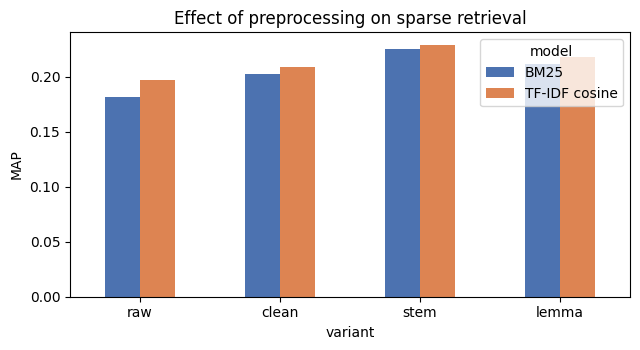

In [7]:
index_by_variant = {v: SparseIndex(DOC_TOK[v]) for v in VARIANTS}
rows = []
for v in VARIANTS:
    tfidf_r, bm25_r = TfidfRanker(index_by_variant[v]), BM25Ranker(index_by_variant[v])
    for mname, ranker in [("TF-IDF cosine", tfidf_r), ("BM25", bm25_r)]:
        S = ranker.score([query_tokens(t, v) for t in QUERY_TEXTS])[EVAL_ROWS]
        m = summarize(per_query_metrics(S)); rows.append({"model": mname, "variant": v, "vocab": index_by_variant[v].V,
                                                          "MAP": m["MAP"], "nDCG@10": m["nDCG@10"], "P@10": m["P@10"], "R@10": m["R@10"]})
prep_df = pd.DataFrame(rows)
display(prep_df.pivot(index="variant", columns="model", values="MAP").loc[VARIANTS].round(4).rename_axis(columns="MAP"))
display(prep_df.round(4))

BEST_VARIANT = prep_df.groupby("variant")["MAP"].mean().idxmax()
print(f"Variant with the best average MAP over the two sparse models: '{BEST_VARIANT}'  (used for all sparse systems below)")

ax = prep_df.pivot(index="variant", columns="model", values="MAP").loc[VARIANTS].plot.bar(figsize=(6.5, 3.6), rot=0, color=["#4C72B0", "#DD8452"])
ax.set_ylabel("MAP"); ax.set_title("Effect of preprocessing on sparse retrieval"); plt.tight_layout(); plt.show()

In [8]:
# Ablation: abstract only (no title) -- same pipeline, only the indexed text changes
abs_vars = [cached_variants(t, want_lemma=False) for t in docs.abstract.tolist()]
pickle.dump(_CACHE, open(CACHE_FILE, "wb"))
ab_rows = []
for v in ["clean", "stem"]:
    idx_abs = SparseIndex([d[v] for d in abs_vars])
    for mname, ranker in [("TF-IDF cosine", TfidfRanker(idx_abs)), ("BM25", BM25Ranker(idx_abs))]:
        S = ranker.score([query_tokens(t, v) for t in QUERY_TEXTS])[EVAL_ROWS]
        ab_rows.append({"variant": v, "model": mname, "indexed text": "abstract only", "MAP": summarize(per_query_metrics(S))["MAP"]})
        ab_rows.append({"variant": v, "model": mname, "indexed text": "title + abstract",
                        "MAP": prep_df[(prep_df.variant == v) & (prep_df.model == mname)]["MAP"].iloc[0]})
display(pd.DataFrame(ab_rows).pivot_table(index=["variant", "model"], columns="indexed text", values="MAP").round(4))

indexed text           abstract only  title + abstract
variant model                                         
clean   BM25                  0.1848            0.2023
        TF-IDF cosine         0.1842            0.2091
stem    BM25                  0.2109            0.2250
        TF-IDF cosine         0.2158            0.2291

## 5.2 Models and representations compared
All systems use default hyper-parameters here (tuning is studied separately in 5.3). Sparse systems use the best preprocessing variant from 5.1;
word-vector systems use **lemmas** (so that terms can be found in the GloVe vocabulary). Word2Vec is trained on the collection itself (skip-gram, 200-d, window 8, 40 epochs) — a deliberately small-corpus setting.

In [9]:
# ---------------- sparse systems ----------------
idx = index_by_variant[BEST_VARIANT]
tfidf_main = TfidfRanker(idx)
bigram_idx = SparseIndex(DOC_TOK[BEST_VARIANT], analyzer=lambda toks: toks + [a + "_" + b for a, b in zip(toks, toks[1:])])
tfidf_bigram = TfidfRanker(bigram_idx)
bm25_default = BM25Ranker(idx, k1=1.2, b=0.75)
lsa_main = LsaRanker(tfidf_main, k_max=500)
LSA_K_DEFAULT = 200

register(System(f"TF-IDF cosine ({BEST_VARIANT})", "sparse", tfidf_main.score, BEST_VARIANT))
register(System(f"TF-IDF cosine 1-2gram ({BEST_VARIANT})", "sparse", tfidf_bigram.score, BEST_VARIANT))
register(System(f"BM25 k1=1.2 b=0.75 ({BEST_VARIANT})", "sparse", bm25_default.score, BEST_VARIANT))
bm25_binary = BM25Ranker(idx, k1=1.2, b=0.75, qtf="binary")          # ablation: query-term presence only
register(System(f"BM25 binary query-tf k1=1.2 b=0.75 ({BEST_VARIANT})", "sparse", bm25_binary.score, BEST_VARIANT))
register(System(f"LSA k={LSA_K_DEFAULT}", "dense (latent)", lambda q: lsa_main.score(q, LSA_K_DEFAULT), BEST_VARIANT))

# ---------------- word-vector systems (lemma tokens) ----------------
from gensim.models import Word2Vec
import gensim.downloader as gensim_api

lemma_idx = index_by_variant["lemma"]
lemma_tf = TfidfTransformer(sublinear_tf=True, smooth_idf=True).fit(lemma_idx.C)
IDF = dict(zip(lemma_idx.cv.get_feature_names_out(), lemma_tf.idf_))
IDF_DEFAULT = np.log((1 + lemma_idx.N) / 1) + 1                     # idf of a term that never occurs in the collection

t0 = time.time()
w2v = Word2Vec(sentences=DOC_TOK["lemma"], vector_size=200, window=8, min_count=2, sg=1, negative=10, epochs=40, seed=SEED, workers=1)
print(f"Word2Vec trained in {time.time() - t0:.0f}s | vocabulary {len(w2v.wv)} | sample neighbours of 'retrieval':",
      [w for w, _ in w2v.wv.most_similar("retrieval", topn=5)] if "retrieval" in w2v.wv else "n/a")

for pooling, idfw in [("mean", None), ("idf-weighted", IDF)]:
    r = WordVecRanker(w2v.wv, DOC_TOK["lemma"], idf=idfw, idf_default=IDF_DEFAULT)
    register(System(f"Word2Vec-CISI {pooling}", "dense (word vectors)", r.score, "lemma"))

GLOVE_KV = {}
for gname in GLOVE_MODELS:
    t0 = time.time(); kv = gensim_api.load(gname); GLOVE_KV[gname] = kv
    cover = np.mean([t in kv for t in set(t for d in DOC_TOK["lemma"] for t in d)])
    print(f"{gname}: loaded in {time.time() - t0:.0f}s | vocabulary coverage of the collection: {cover:.1%}")
    short = "GloVe-" + gname.split("-")[-1]
    for pooling, idfw in [("mean", None), ("idf-weighted", IDF)]:
        r = WordVecRanker(kv, DOC_TOK["lemma"], idf=idfw, idf_default=IDF_DEFAULT)
        register(System(f"{short} {pooling}", "dense (word vectors)", r.score, "lemma"))

Word2Vec trained in 65s | vocabulary 4436 | sample neighbours of 'retrieval': ['system', 'supars', 'information', 'matching', 'compatibility']


glove-wiki-gigaword-100: loaded in 31s | vocabulary coverage of the collection: 94.0%


glove-wiki-gigaword-300: loaded in 94s | vocabulary coverage of the collection: 94.0%


In [10]:
# ---------------- optional: sentence-transformer (needs `pip install sentence-transformers` + model download) ----------------
SBERT_OK = False
if USE_SBERT:
    try:
        from sentence_transformers import SentenceTransformer
        _sb = SentenceTransformer(SBERT_MODEL)
        _E = _sb.encode(DOC_TEXT, normalize_embeddings=True, show_progress_bar=False, batch_size=64)
        register(System(f"SBERT {SBERT_MODEL}", "dense (contextual)",
                        lambda texts: _sb.encode(list(texts), normalize_embeddings=True, show_progress_bar=False) @ _E.T, None))
        SBERT_OK = True
    except Exception as e:
        print(f"Sentence-transformers skipped ({type(e).__name__}): install it and allow the model download to include a contextual dense model.")
print("SBERT available:", SBERT_OK)

Sentence-transformers skipped (ModuleNotFoundError): install it and allow the model download to include a contextual dense model.
SBERT available: False


In [11]:
# ---------------- hybrids: best sparse (BM25) + best dense word-vector model, chosen by MAP among the registered systems ----------------
dense_names = [n for n, s in SYSTEMS.items() if s.family in ("dense (word vectors)", "dense (contextual)")]   # embedding-based models only
best_dense = max(dense_names, key=lambda n: PQ[n]["AP"].mean())
sparse_ref = f"BM25 k1=1.2 b=0.75 ({BEST_VARIANT})"
print("Best dense system (by MAP):", best_dense, "| sparse partner:", sparse_ref)

register(System(f"Hybrid RRF: BM25 + {best_dense}", "hybrid",
                lambda texts: rrf([SYSTEMS[sparse_ref].score_texts(texts), SYSTEMS[best_dense].score_texts(texts)]), None))
register(System(f"Hybrid z-fusion a=0.5: BM25 + {best_dense}", "hybrid",
                lambda texts: zfuse(SYSTEMS[sparse_ref].score_texts(texts), SYSTEMS[best_dense].score_texts(texts), 0.5), None))
print(len(SYSTEMS), "systems registered")

Best dense system (by MAP): Word2Vec-CISI idf-weighted | sparse partner: BM25 k1=1.2 b=0.75 (stem)
13 systems registered


,family,P@5,P@10,P@20,R@5,R@10,R@20,F1@5,F1@10,F1@20,MAP,nDCG@10,MRR
LSA k=200,dense (latent),0.403,0.366,0.291,0.087,0.142,0.203,0.118,0.170,0.198,0.239,0.398,0.616
Hybrid z-fusion a=0.5: BM25 + Word2Vec-CISI idf-weighted,hybrid,0.434,0.366,0.301,0.080,0.142,0.213,0.124,0.170,0.208,0.237,0.411,0.679
Hybrid RRF: BM25 + Word2Vec-CISI idf-weighted,hybrid,0.421,0.349,0.289,0.086,0.139,0.205,0.120,0.165,0.200,0.231,0.394,0.652
TF-IDF cosine (stem),sparse,0.408,0.354,0.286,0.078,0.134,0.204,0.119,0.171,0.198,0.229,0.400,0.679
BM25 k1=1.2 b=0.75 (stem),sparse,0.429,0.367,0.291,0.095,0.147,0.205,0.131,0.175,0.201,0.225,0.405,0.662
TF-IDF cosine 1-2gram (stem),sparse,0.347,0.299,0.256,0.074,0.117,0.198,0.111,0.147,0.184,0.209,0.329,0.579
Word2Vec-CISI idf-weighted,dense (word vectors),0.332,0.316,0.242,0.057,0.121,0.167,0.090,0.146,0.164,0.185,0.340,0.558
Word2Vec-CISI mean,dense (word vectors),0.347,0.292,0.238,0.053,0.105,0.159,0.086,0.127,0.158,0.181,0.321,0.531
BM25 binary query-tf k1=1.2 b=0.75 (stem),sparse,0.347,0.303,0.249,0.060,0.110,0.168,0.093,0.132,0.167,0.179,0.333,0.589
GloVe-300 idf-weighted,dense (word vectors),0.347,0.291,0.228,0.055,0.094,0.141,0.088,0.126,0.151,0.164,0.323,0.567


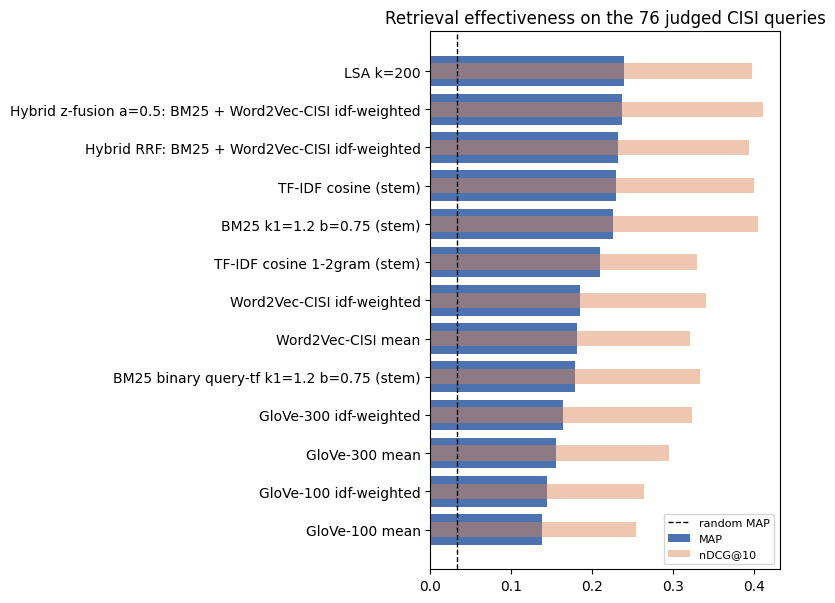

In [12]:
# ---------------- main results table ----------------
METRIC_ORDER = [f"{m}@{k}" for m in ("P", "R", "F1") for k in KS] + ["MAP", "nDCG@10", "MRR"]
def results_table(names):
    t = pd.DataFrame({n: summarize(PQ[n]) for n in names}).T[METRIC_ORDER]
    t.insert(0, "family", [SYSTEMS[n].family for n in names])
    return t

main = results_table(list(SYSTEMS)).sort_values("MAP", ascending=False)
rand_row = RANDOM_ROW.rename({"AP": "MAP", "RR": "MRR"})[METRIC_ORDER]
main.loc["Random ranking (mean of 20)"] = ["chance"] + list(rand_row.values)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
display(main.round(3))
main.round(4).to_csv("ir_results_main.csv")
pd.DataFrame({n: PQ[n]["AP"] for n in SYSTEMS}).round(4).to_csv("ir_per_query_AP.csv")

top = main.drop("Random ranking (mean of 20)").sort_values("MAP")
fig, ax = plt.subplots(figsize=(8, 0.38 * len(top) + 1.2))
ax.barh(top.index, top["MAP"], color="#4C72B0", label="MAP"); ax.barh(top.index, top["nDCG@10"], color="#DD8452", alpha=0.45, height=0.4, label="nDCG@10")
ax.axvline(RANDOM_ROW["MAP"], color="k", ls="--", lw=1, label="random MAP"); ax.legend(loc="lower right", fontsize=8)
ax.set_title("Retrieval effectiveness on the 76 judged CISI queries"); plt.tight_layout(); plt.show()

,MAP,MAP 2.5%,MAP 97.5%
LSA k=200,0.239,0.204,0.281
Hybrid z-fusion a=0.5: BM25 + Word2Vec-CISI idf-weighted,0.237,0.205,0.273
Hybrid RRF: BM25 + Word2Vec-CISI idf-weighted,0.231,0.201,0.268
TF-IDF cosine (stem),0.229,0.196,0.268
BM25 k1=1.2 b=0.75 (stem),0.225,0.193,0.263
TF-IDF cosine 1-2gram (stem),0.209,0.178,0.244
Word2Vec-CISI idf-weighted,0.185,0.157,0.217
Word2Vec-CISI mean,0.181,0.153,0.213
BM25 binary query-tf k1=1.2 b=0.75 (stem),0.179,0.156,0.205
GloVe-300 idf-weighted,0.164,0.139,0.191


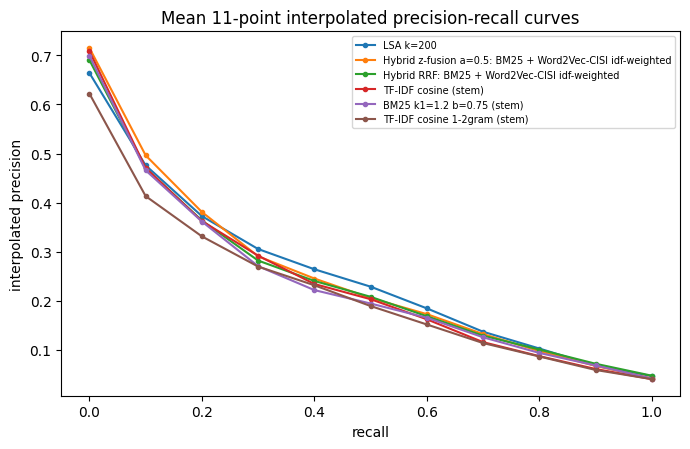

In [13]:
# ---------------- uncertainty: bootstrap 95% CI of MAP over queries, and interpolated precision-recall curves ----------------
def boot_ci(x, n=5000, seed=0):
    r = np.random.RandomState(seed); m = x[r.randint(0, len(x), (n, len(x)))].mean(1)
    return np.percentile(m, [2.5, 97.5])
ci = pd.DataFrame({n: boot_ci(PQ[n]["AP"].values) for n in SYSTEMS}, index=["MAP 2.5%", "MAP 97.5%"]).T
display(pd.concat([main.loc[list(SYSTEMS), ["MAP"]], ci], axis=1).sort_values("MAP", ascending=False).round(3))

show = list(main.drop("Random ranking (mean of 20)").index[:6])
for must in [f"TF-IDF cosine ({BEST_VARIANT})", sparse_ref]:
    if must not in show: show.append(must)
fig, ax = plt.subplots(figsize=(7, 4.6))
for n in show: ax.plot(np.linspace(0, 1, 11), interpolated_pr(SCORES[n]), marker="o", ms=3, label=n)
ax.set_xlabel("recall"); ax.set_ylabel("interpolated precision"); ax.set_title("Mean 11-point interpolated precision-recall curves")
ax.legend(fontsize=7); plt.tight_layout(); plt.show()

## 5.3 Hyper-parameter tuning with cross-validation over queries
Tuning on the same 76 queries that are then used to report performance is optimistic. We therefore use **repeated 5-fold cross-validation over queries** (10 repeats):
in each fold the configuration with the best mean AP on the training queries is selected and evaluated on the held-out queries. The *CV-MAP* is the honest estimate of the tuned system;
the "in-sample best" is shown only for reference. Grids: BM25 `k1 × b` (35 configurations), LSA dimensionality `k`, and the z-fusion weight `alpha` (BM25 vs. best dense model).

In [14]:
def repeated_cv_select(ap_grid, n_splits=5, n_repeats=10, seed=SEED):
    '''ap_grid: DataFrame (configs x queries) of per-query AP. Returns CV-MAP (mean, std over repeats) and how often each config is selected.'''
    A = ap_grid.values; n_q = A.shape[1]; cv_scores, picks = [], []
    rkf = RepeatedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=seed)
    held = np.zeros((n_repeats, n_q)); r_i = 0
    for fold_no, (tr, te) in enumerate(rkf.split(np.arange(n_q))):
        best = A[:, tr].mean(1).argmax(); picks.append(ap_grid.index[best])
        held[fold_no // n_splits, te] = A[best, te]
    cv = held.mean(1)
    return cv.mean(), cv.std(), pd.Series(picks).value_counts()

tuning = {}
# ---- BM25 grid ----
K1S, BS = [0.6, 0.9, 1.2, 1.5, 2.0, 3.0, 5.0], [0.25, 0.5, 0.75, 0.9, 1.0]
qtok = [query_tokens(t, BEST_VARIANT) for t in QUERY_TEXTS]
bm_ap = {}
for k1 in K1S:
    for b in BS:
        bm_ap[(k1, b)] = per_query_metrics(BM25Ranker(idx, k1, b).score(qtok)[EVAL_ROWS])["AP"].values
bm_ap = pd.DataFrame(bm_ap).T
bm_ap.index = [f"k1={k1}, b={b}" for k1, b in bm_ap.index]
BM_BEST = bm_ap.mean(1).idxmax()
_cv = repeated_cv_select(bm_ap)
tuning["BM25 (k1, b)"] = (bm_ap.loc["k1=1.2, b=0.75"].mean(), bm_ap.mean(1).max(), BM_BEST, _cv[0], _cv[1], _cv[2].index[0])
display(pd.DataFrame(bm_ap.mean(1).values.reshape(len(K1S), len(BS)), index=[f"k1={k}" for k in K1S], columns=[f"b={b}" for b in BS]).round(4).rename_axis("MAP (in-sample)"))

# ---- LSA dimensionality ----
LSA_KS = [25, 50, 100, 150, 200, 300, 400, 500]
lsa_ap = pd.DataFrame({f"k={k}": per_query_metrics(lsa_main.score(qtok, k)[EVAL_ROWS])["AP"].values for k in LSA_KS}).T
_cv = repeated_cv_select(lsa_ap)
tuning["LSA (k)"] = (lsa_ap.loc[f"k={LSA_K_DEFAULT}"].mean(), lsa_ap.mean(1).max(), lsa_ap.mean(1).idxmax(), _cv[0], _cv[1], _cv[2].index[0])

# ---- fusion weight (BM25 default + best dense) ----
S_sp = SYSTEMS[sparse_ref].score_texts(QUERY_TEXTS)[EVAL_ROWS]; S_de = SYSTEMS[best_dense].score_texts(QUERY_TEXTS)[EVAL_ROWS]
ALPHAS = np.round(np.arange(0, 1.01, 0.1), 1)
fu_ap = pd.DataFrame({f"alpha={a}": per_query_metrics(zfuse(S_sp, S_de, a))["AP"].values for a in ALPHAS}).T
_cv = repeated_cv_select(fu_ap)
tuning["z-fusion (alpha)"] = (fu_ap.loc["alpha=0.5"].mean(), fu_ap.mean(1).max(), fu_ap.mean(1).idxmax(), _cv[0], _cv[1], _cv[2].index[0])

tune_tab = pd.DataFrame(tuning, index=["default MAP", "in-sample best MAP (optimistic)", "in-sample best config", "CV-MAP (honest)", "CV-MAP std", "most selected config"]).T
display(tune_tab)

,b=0.25,b=0.5,b=0.75,b=0.9,b=1.0
MAP (in-sample),,,,,
k1=0.6,0.2025,0.2106,0.2137,0.2154,0.2160
k1=0.9,0.2099,0.2157,0.2213,0.2224,0.2216
k1=1.2,0.2153,0.2209,0.2250,0.2242,0.2252
k1=1.5,0.2168,0.2231,0.2267,0.2258,0.2262
k1=2.0,0.2226,0.2293,0.2295,0.2299,0.2302
k1=3.0,0.2238,0.2301,0.2321,0.2328,0.2314
k1=5.0,0.2233,0.2301,0.2341,0.2314,0.2286


,default MAP,in-sample best MAP (optimistic),in-sample best config,CV-MAP (honest),CV-MAP std,most selected config
"BM25 (k1, b)",0.225007,0.234062,"k1=5.0, b=0.75",0.230991,0.002358,"k1=5.0, b=0.75"
LSA (k),0.239319,0.239319,k=200,0.230981,0.003561,k=200
z-fusion (alpha),0.236555,0.236555,alpha=0.5,0.235164,0.001006,alpha=0.5


In [15]:
# Register the tuned systems (configuration chosen on all 76 queries -> optimistic; see the CV-MAP column above for the honest estimate)
m = re.match(r"k1=([\d.]+), b=([\d.]+)", BM_BEST); k1_best, b_best = float(m.group(1)), float(m.group(2))
bm25_tuned = BM25Ranker(idx, k1_best, b_best)
register(System(f"BM25 tuned k1={k1_best} b={b_best} (in-sample)", "sparse", bm25_tuned.score, BEST_VARIANT))
k_best = int(tuning["LSA (k)"][2].split("=")[1])
register(System(f"LSA tuned k={k_best} (in-sample)", "dense (latent)", lambda q: lsa_main.score(q, k_best), BEST_VARIANT))
a_best = float(tuning["z-fusion (alpha)"][2].split("=")[1])
register(System(f"Hybrid z-fusion tuned a={a_best} (in-sample)", "hybrid",
                lambda texts: zfuse(SYSTEMS[sparse_ref].score_texts(texts), SYSTEMS[best_dense].score_texts(texts), a_best), None))
display(results_table(list(SYSTEMS)[-3:]).round(3))

,family,P@5,P@10,P@20,R@5,R@10,R@20,F1@5,F1@10,F1@20,MAP,nDCG@10,MRR
BM25 tuned k1=5.0 b=0.75 (in-sample),sparse,0.421,0.367,0.297,0.083,0.139,0.213,0.126,0.177,0.206,0.234,0.402,0.648
LSA tuned k=200 (in-sample),dense (latent),0.403,0.366,0.291,0.087,0.142,0.203,0.118,0.170,0.198,0.239,0.398,0.616
Hybrid z-fusion tuned a=0.5 (in-sample),hybrid,0.434,0.366,0.301,0.080,0.142,0.213,0.124,0.170,0.208,0.237,0.411,0.679


## 5.4 Statistical significance
With 76 queries, differences of a few MAP points can be noise. For selected pairs of systems we report the mean paired difference in per-query AP with a **bootstrap 95 % CI** (10,000 resamples of queries) and a
**Wilcoxon signed-rank** p-value (two-sided; no correction for multiple comparisons — interpret as exploratory).

In [16]:
def paired_test(a, b, n=10000, seed=0):
    d = (PQ[a]["AP"] - PQ[b]["AP"]).values
    r = np.random.RandomState(seed); means = d[r.randint(0, len(d), (n, len(d)))].mean(1)
    try: p = stats.wilcoxon(d).pvalue
    except ValueError: p = np.nan
    return {"A": a, "B": b, "mean dAP (A-B)": d.mean(), "CI 2.5%": np.percentile(means, 2.5), "CI 97.5%": np.percentile(means, 97.5),
            "Wilcoxon p": p, "A wins / B wins": f"{(d > 1e-12).sum()} / {(d < -1e-12).sum()}"}

tf_n, bm_n = f"TF-IDF cosine ({BEST_VARIANT})", sparse_ref
hyb_rrf = [n for n in SYSTEMS if n.startswith("Hybrid RRF")][0]
pairs = [(bm_n, tf_n), (f"LSA k={LSA_K_DEFAULT}", tf_n), (best_dense, bm_n), (best_dense, tf_n), (hyb_rrf, bm_n), (hyb_rrf, best_dense)]
gl = [n for n in SYSTEMS if n.startswith("GloVe-300")]
if len(gl) == 2: pairs.append((gl[1], gl[0]))
sig = pd.DataFrame([paired_test(a, b) for a, b in pairs]); display(sig.round(4))

,A,B,mean dAP (A-B),CI 2.5%,CI 97.5%,Wilcoxon p,A wins / B wins
0,BM25 k1=1.2 b=0.75 (stem),TF-IDF cosine (stem),-0.0041,-0.0170,0.0078,0.6749,37 / 39
1,LSA k=200,TF-IDF cosine (stem),0.0102,-0.0041,0.0278,0.2378,47 / 29
2,Word2Vec-CISI idf-weighted,BM25 k1=1.2 b=0.75 (stem),-0.0399,-0.0635,-0.0194,0.0013,26 / 50
3,Word2Vec-CISI idf-weighted,TF-IDF cosine (stem),-0.0440,-0.0689,-0.0213,0.0032,31 / 45
4,Hybrid RRF: BM25 + Word2Vec-CISI idf-weighted,BM25 k1=1.2 b=0.75 (stem),0.0063,-0.0093,0.0211,0.0895,43 / 33
5,Hybrid RRF: BM25 + Word2Vec-CISI idf-weighted,Word2Vec-CISI idf-weighted,0.0462,0.0330,0.0616,0.0000,61 / 15
6,GloVe-300 idf-weighted,GloVe-300 mean,0.0090,-0.0038,0.0223,0.3278,43 / 33


## 5.5 Per-query analysis
Where do the systems differ, and why? We look at the distribution of AP per query, the relation between AP and the number of relevant documents, and the queries on which a dense model beats BM25 (and vice versa).

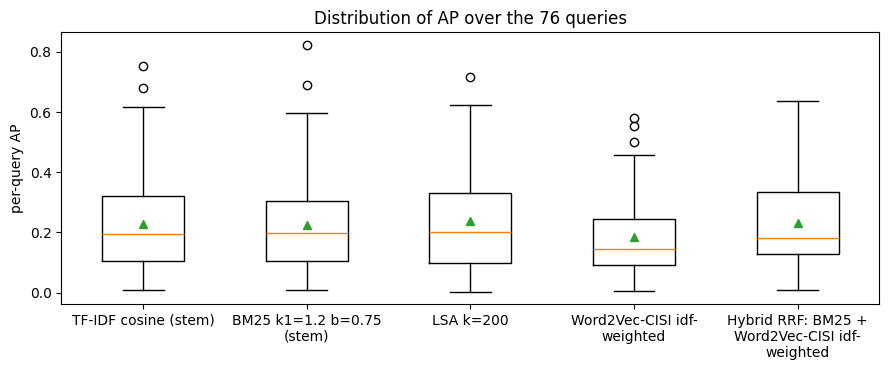

BM25: Spearman(AP, #relevant docs) = 0.34 (p=0.003) | Spearman(AP, query length) = 0.08 (p=0.500)
Share of queries with AP < 0.1 under BM25: 22% | under Word2Vec-CISI idf-weighted: 32%

Queries where the dense model (Word2Vec-CISI idf-weighted) beats BM25 the most:
  q98   dAP=+0.10 | AP bm25=0.46, dense=0.55 | n_rel=29 | Online retrieval systems may be difficult to use, especially by end users, because of heterogeneity and [...]
  q21   dAP=+0.09 | AP bm25=0.12, dense=0.21 | n_rel=25 | The need to provide personnel for the information field.
  q30   dAP=+0.09 | AP bm25=0.32, dense=0.42 | n_rel=134 | Information dissemination by journals and periodicals.
Queries where BM25 beats the dense model the most:
  q62   dAP=-0.55 | AP bm25=0.69, dense=0.14 | n_rel=12 | This article concerns the problem of how to permit a patron to represent the relative importance of [...]
  q55   dAP=-0.37 | AP bm25=0.82, dense=0.46 | n_rel=18 | What are the aims and objectives of the medical literature analy

In [17]:
box_names = [tf_n, bm_n, f"LSA k={LSA_K_DEFAULT}", best_dense, hyb_rrf]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.boxplot([PQ[n]["AP"].values for n in box_names], labels=[textwrap.fill(n, 22) for n in box_names], showmeans=True)
ax.set_ylabel("per-query AP"); ax.set_title("Distribution of AP over the 76 queries"); plt.tight_layout(); plt.show()

ap_bm = PQ[bm_n]["AP"]
rho_rel = stats.spearmanr(ap_bm.values, N_REL); qlen = np.array([len(query_tokens(QUERY_TEXTS[r], BEST_VARIANT)) for r in EVAL_ROWS])
rho_len = stats.spearmanr(ap_bm.values, qlen)
print(f"BM25: Spearman(AP, #relevant docs) = {rho_rel.correlation:.2f} (p={rho_rel.pvalue:.3f}) | Spearman(AP, query length) = {rho_len.correlation:.2f} (p={rho_len.pvalue:.3f})")
print(f"Share of queries with AP < 0.1 under BM25: {(ap_bm < 0.1).mean():.0%} | under {best_dense}: {(PQ[best_dense]['AP'] < 0.1).mean():.0%}")

diff = (PQ[best_dense]["AP"] - ap_bm).sort_values()
def show_q(qid, d):
    r = int(np.where(Q_IDS == qid)[0][0])
    print(f"  q{qid:<4} dAP={d:+.2f} | AP bm25={ap_bm[qid]:.2f}, dense={PQ[best_dense]['AP'][qid]:.2f} | n_rel={int(N_REL[list(EVAL_QIDS).index(qid)])} | " + textwrap.shorten(QUERY_TEXTS[r], 110, placeholder=' [...]'))
print(f"\nQueries where the dense model ({best_dense}) beats BM25 the most:")
for q, d in diff[::-1].head(3).items(): show_q(q, d)
print("Queries where BM25 beats the dense model the most:")
for q, d in diff.head(3).items(): show_q(q, d)

# 6. Natural-language search engine
Because every system implements `score_texts(texts)`, a user can type **any free-text question**: it is preprocessed exactly like the documents and mapped into the same space
(sparse term space, LSA space, or word-vector space) before scoring. `search()` below returns the top-k titles; for a CISI query id the judged-relevant documents are marked with ✓.

In [18]:
def search(query, system_name, top_k=5, qid=None):
    '''Rank the collection for a free-text query with the chosen system and print the top_k results.'''
    S = SYSTEMS[system_name].score_texts([query])[0]
    top = np.argsort(-S, kind="stable")[:top_k]
    relevant = set(rel_df.loc[rel_df.qid == qid, "doc_id"]) if qid is not None else set()
    for r, i in enumerate(top, 1):
        mark = "✓" if D_IDS[i] in relevant else (" " if qid is not None else "")
        print(f"  {r}. {mark} [{S[i]:.3f}] doc {D_IDS[i]:>4}: {textwrap.shorten(docs.title.iloc[i], 85, placeholder='…')}")

demo_systems = [tf_n, bm_n, best_dense, hyb_rrf]
for q in ["How are computers used to automatically index and classify library documents?",
          "problems of scientific journals growth and how researchers keep up with the literature"]:
    print("\nQUERY:", q)
    for sname in demo_systems:
        print(f" -> {sname}"); search(q, sname, top_k=4)

print("\n\nCISI query 44 with relevance marks (✓ = judged relevant):")
for sname in [bm_n, best_dense]:
    print(f" -> {sname}"); search(QUERY_TEXTS[list(Q_IDS).index(44)], sname, top_k=5, qid=44)


QUERY: How are computers used to automatically index and classify library documents?
 -> TF-IDF cosine (stem)


  1.  [0.381] doc  662: Automatic Indexing: An Experimental Inquiry
  2.  [0.373] doc  663: Automatic Document Classification Part II. Additional Experiments
  3.  [0.368] doc  564: Automatic Document Classification
  4.  [0.349] doc  565: Computer Evaluation of Indexing and Text Processing
 -> BM25 k1=1.2 b=0.75 (stem)
  1.  [16.711] doc  662: Automatic Indexing: An Experimental Inquiry
  2.  [16.382] doc  564: Automatic Document Classification
  3.  [14.482] doc  663: Automatic Document Classification Part II. Additional Experiments
  4.  [14.177] doc  503: Automatic Classification and Retrieval of Documents by Means of a Bibliographic…
 -> Word2Vec-CISI idf-weighted
  1.  [0.815] doc  663: Automatic Document Classification Part II. Additional Experiments
  2.  [0.777] doc  790: Computer Indexing of Medical Articles - Project Medico
  3.  [0.775] doc  564: Automatic Document Classification
  4.  [0.768] doc  662: Automatic Indexing: An Experimental Inquiry
 -> Hybrid RRF: BM25 + Word

# 7. Boolean retrieval baseline (`CISI.BLN`)
Boolean retrieval returns an **unranked set**: the documents that satisfy an expression with `AND`, `OR`, `NOT` and parentheses (precedence NOT > AND > OR), evaluated on an inverted index of the stemmed collection.
Its effectiveness is therefore measured with *set-based* precision, recall and F1, not with rank metrics.

*Note:* `CISI.BLN` was not available in the copy used to develop this notebook, so (a) the evaluator is demonstrated on **hand-written** Boolean formulations of CISI information needs (not the official ones),
and (b) if `CISI.BLN` is present in `DATA_DIR`, a lenient loader prints its first lines and tries to evaluate every `.I id` + expression; **check the printed head to verify the format assumption** (one expression per `.I` block).

In [19]:
POSTINGS = {}
for i, toks in enumerate(DOC_TOK["stem"]):
    for t in set(toks): POSTINGS.setdefault(t, set()).add(i)
ALL_DOCS = set(range(D))

def boolean_retrieve(expr):
    '''Evaluate a Boolean expression (AND / OR / NOT / parentheses) over the stemmed inverted index; returns a set of document positions.'''
    toks = re.findall(r"\(|\)|[A-Za-z0-9_']+", expr)
    pos = 0
    def peek(): return toks[pos] if pos < len(toks) else None
    def eat(): nonlocal pos; pos += 1; return toks[pos - 1]
    def parse_or():
        res = parse_and()
        while peek() and peek().upper() == "OR": eat(); res = res | parse_and()
        return res
    def parse_and():
        res = parse_not()
        while peek() and peek().upper() == "AND": eat(); res = res & parse_not()
        return res
    def parse_not():
        if peek() and peek().upper() == "NOT": eat(); return ALL_DOCS - parse_not()
        return parse_atom()
    def parse_atom():
        t = eat()
        if t == "(":
            res = parse_or(); eat(); return res          # consume ")"
        term = porter.stem(re.sub(r"[^a-z0-9]", "", t.lower()))
        return set(POSTINGS.get(term, set()))
    return parse_or()

def eval_boolean(expr, qid):
    got = {D_IDS[i] for i in boolean_retrieve(expr)}; rel = set(rel_df.loc[rel_df.qid == qid, "doc_id"])
    tp = len(got & rel); p = tp / len(got) if got else 0.0; r = tp / len(rel) if rel else 0.0
    return {"qid": qid, "expression": expr, "retrieved": len(got), "relevant": len(rel), "P": p, "R": r, "F1": 2 * p * r / (p + r) if p + r else 0.0}

demo = [(44, "(journal OR journals OR publication) AND (retrieval OR storage OR indexing)"),
        (44, "journal AND retrieval"),
        (44, "(scientific OR technical) AND (publication OR literature) AND NOT catalog")]
bool_demo = pd.DataFrame([eval_boolean(e, q) for q, e in demo]); display(bool_demo.round(3))

# ranked retrieval on the same information need, cut at the same number of documents (set-size matched precision)
for n_ret, (q, e) in zip(bool_demo.retrieved, demo):
    row = list(EVAL_QIDS).index(q); S = SCORES[bm_n][row]; top = np.argsort(-S, kind="stable")[:max(n_ret, 1)]
    print(f"BM25 top-{max(n_ret, 1)} (same set size as the Boolean answer): precision = {REL[row, top].mean():.3f}")

bln_path = f"{DATA_DIR}/CISI.BLN"
if os.path.exists(bln_path) and os.path.getsize(bln_path) > 100:
    raw_bln = open(bln_path, encoding="utf-8", errors="replace").read().replace("\r\n", "\n")
    print("\nCISI.BLN head:\n", raw_bln[:400])
    results_bln = []
    for rec in re.split(r"(?m)^\.I\s+", raw_bln)[1:]:
        qid_s, _, body = rec.partition("\n"); body = re.sub(r"(?m)^\.[A-Z]\s*", " ", body).strip()
        try:
            if int(qid_s) in set(EVAL_QIDS) and body: results_bln.append(eval_boolean(body, int(qid_s)))
        except Exception as e: print("could not parse query", qid_s, "->", type(e).__name__)
    if results_bln:
        bln_df = pd.DataFrame(results_bln); print(f"\nBoolean baseline on {len(bln_df)} CISI.BLN queries: mean P={bln_df.P.mean():.3f}, R={bln_df.R.mean():.3f}, F1={bln_df.F1.mean():.3f}")
else:
    print("\nCISI.BLN not found (or empty) in DATA_DIR -> official Boolean queries not evaluated.")

,qid,expression,retrieved,relevant,P,R,F1
0,44,(journal OR journals OR publication) AND (retr...,91,155,0.308,0.181,0.228
1,44,journal AND retrieval,18,155,0.278,0.032,0.058
2,44,(scientific OR technical) AND (publication OR ...,107,155,0.355,0.245,0.290


BM25 top-91 (same set size as the Boolean answer): precision = 0.396
BM25 top-18 (same set size as the Boolean answer): precision = 0.667
BM25 top-107 (same set size as the Boolean answer): precision = 0.374

CISI.BLN not found (or empty) in DATA_DIR -> official Boolean queries not evaluated.


# 8. Consolidated comparison, discussion and conclusions

In [20]:
final = results_table(list(SYSTEMS)).sort_values("MAP", ascending=False)
final = final[["family", "P@5", "P@10", "R@10", "F1@5", "F1@10", "MAP", "nDCG@10", "MRR"]]
final.loc["Random ranking (mean of 20)"] = ["chance"] + [rand_row[c] for c in final.columns[1:]]
display(final.round(3)); final.round(4).to_csv("ir_results_consolidated.csv")

,family,P@5,P@10,R@10,F1@5,F1@10,MAP,nDCG@10,MRR
LSA k=200,dense (latent),0.403,0.366,0.142,0.118,0.170,0.239,0.398,0.616
LSA tuned k=200 (in-sample),dense (latent),0.403,0.366,0.142,0.118,0.170,0.239,0.398,0.616
Hybrid z-fusion a=0.5: BM25 + Word2Vec-CISI idf-weighted,hybrid,0.434,0.366,0.142,0.124,0.170,0.237,0.411,0.679
Hybrid z-fusion tuned a=0.5 (in-sample),hybrid,0.434,0.366,0.142,0.124,0.170,0.237,0.411,0.679
BM25 tuned k1=5.0 b=0.75 (in-sample),sparse,0.421,0.367,0.139,0.126,0.177,0.234,0.402,0.648
Hybrid RRF: BM25 + Word2Vec-CISI idf-weighted,hybrid,0.421,0.349,0.139,0.120,0.165,0.231,0.394,0.652
TF-IDF cosine (stem),sparse,0.408,0.354,0.134,0.119,0.171,0.229,0.400,0.679
BM25 k1=1.2 b=0.75 (stem),sparse,0.429,0.367,0.147,0.131,0.175,0.225,0.405,0.662
TF-IDF cosine 1-2gram (stem),sparse,0.347,0.299,0.117,0.111,0.147,0.209,0.329,0.579
Word2Vec-CISI idf-weighted,dense (word vectors),0.332,0.316,0.121,0.090,0.146,0.185,0.340,0.558


## Discussion and conclusions (results of the run above)

**Headline results** (76 judged queries; chance level: MAP 0.032, P@10 0.028):

| System | P@5 | P@10 | F1@10 | MAP | nDCG@10 |
|---|---|---|---|---|---|
| LSA (k = 200) | 0.403 | 0.366 | 0.170 | **0.239** | 0.398 |
| Hybrid z-fusion (BM25 + Word2Vec-CISI idf), α = 0.5 | **0.434** | 0.366 | 0.170 | 0.237 | **0.411** |
| Hybrid RRF (BM25 + Word2Vec-CISI idf) | 0.421 | 0.349 | 0.165 | 0.231 | 0.394 |
| TF-IDF cosine (stemmed) | 0.408 | 0.354 | 0.171 | 0.229 | 0.400 |
| BM25 (k1 = 1.2, b = 0.75) | 0.429 | 0.367 | 0.175 | 0.225 | 0.405 |
| TF-IDF cosine, unigrams + bigrams | 0.347 | 0.299 | 0.147 | 0.209 | 0.329 |
| Word2Vec trained on CISI (idf-weighted mean) | 0.332 | 0.316 | 0.146 | 0.185 | 0.340 |
| BM25 with binary query-term frequency | 0.347 | 0.303 | 0.132 | 0.179 | 0.333 |
| GloVe-300 (idf-weighted mean) | 0.347 | 0.291 | 0.126 | 0.164 | 0.323 |
| GloVe-100 (idf-weighted mean) | 0.268 | 0.226 | 0.094 | 0.144 | 0.264 |

Absolute values are modest because CISI is a hard collection: queries are long natural-language questions (mean 76 words) and an evaluated query has on average 41 relevant documents (maximum 155).
That also bounds recall and F1 at small cut-offs (R@10 ≤ 0.15 for every system), so P/R/F1@k should be read **relatively**; MAP and nDCG are the more informative summaries.

**1. Preprocessing matters more than the choice between sparse ranking functions.** Going from raw tokens to stemmed tokens raises TF-IDF MAP from 0.197 to 0.229 (+3.2 points) and BM25 MAP from 0.181 to 0.225 (+4.4), while shrinking the vocabulary
from 10,111 to 5,718 terms. Lemmatization (0.218 / 0.212) is better than no normalisation but worse than Porter stemming here: stemming conflates more derivational variants (*classification / classify / classified*), which helps recall on short abstracts,
and CISI's vocabulary is mostly plain English. Removing stop-words and numbers alone gives +1.2 / +2.1 points. Indexing the title together with the abstract adds 1.4 – 2.5 points over the abstract alone.
(The variant was chosen on the same queries, so the +0.4 point gap between stemming and lemmatization should be read with caution.)

**2. TF-IDF cosine and BM25 are statistically indistinguishable.** MAP 0.229 vs 0.225, mean paired ΔAP = −0.004 (95 % CI [−0.017, +0.008], Wilcoxon p = 0.67; 37 vs 39 query wins). The one implementation detail that *does* matter is the query side:
because CISI queries are long and repeat their key terms, weighting query terms by their frequency lifts BM25 from MAP 0.179 (binary) to 0.225. Cross-validated tuning prefers a larger `k1` (k1 = 5, b = 0.75): honest CV-MAP 0.231 vs 0.225 for the defaults — a small gain
(+0.6 points), plausible because abstracts are short (≈ 71 tokens after cleaning), so term-frequency saturation is less necessary. Adding bigrams hurts (0.209): with 1,460 short documents the feature space becomes too sparse.

**3. Dense retrieval: latent semantics help slightly, word-vector averaging hurts.** LSA has the best nominal MAP (0.239, 95 % CI [0.204, 0.281]) but its advantage over TF-IDF (+0.010, CI [−0.004, +0.028], p = 0.24) is not significant, and its honest CV-MAP (0.231) equals that of tuned BM25.
The pooled word-vector models are clearly worse than the sparse ones: Word2Vec trained on CISI reaches 0.185 and pretrained GloVe-300 0.164 (GloVe-100: 0.144); e.g. Word2Vec-idf vs BM25: ΔAP = −0.040 (CI [−0.064, −0.019], p = 0.001; 26 vs 50 query wins).
Observations: (i) IDF-weighted pooling is consistently better than the plain mean (e.g. +0.4 to +0.9 MAP points), although the difference is not significant for GloVe-300 (p = 0.33); (ii) 300-d GloVe beats 100-d by about 2 points; (iii) the small **in-domain** Word2Vec model beats the much larger general-domain GloVe vectors even though
GloVe covers 94 % of the collection vocabulary — domain-specific usage (*index, abstract, retrieval, catalog*) is not captured by Wikipedia/Gigaword. Likely reasons (hypotheses, not tested here): averaging dilutes the few discriminative terms of a 70–120-word text and
discards the exact-match signal that is so valuable on this collection; the Word2Vec neighbours learned from 1,460 documents are also noisy (the nearest neighbour list of *retrieval* contains a rare-token artefact).
A contextual sentence-transformer cell is included but could not be executed in the environment used here (no model download), so it is **not** part of these results.

**4. Hybrids give the best early precision, but the gains are small.** Fusing BM25 with Word2Vec by z-score fusion (α = 0.5) gives the best P@5 (0.434), nDCG@10 (0.411) and MRR (0.679) and MAP 0.237; α = 0.5 is also what cross-validation selects (CV-MAP 0.235).
Relative to BM25 alone the difference is not significant (RRF: +0.006, CI [−0.009, +0.021], p = 0.09), but relative to the dense component alone it is large (+0.046, CI [+0.033, +0.062], p < 0.0001; 61 vs 15 wins): the lexical signal repairs most of what averaging loses, while the dense signal adds a little diversity.

**5. Per-query behaviour.** AP varies enormously across queries; 22 % of queries have AP < 0.1 under BM25 (32 % under Word2Vec). AP correlates positively with the number of relevant documents (Spearman ρ = 0.34, p = 0.003: topics with many relevant documents are easier) and not with query length (ρ = 0.08).
BM25 wins by the widest margins on queries with specific, rare vocabulary (e.g. the MEDLARS query: AP 0.82 vs 0.46), whereas the dense model wins, by smaller margins (≤ +0.10), on broad topics such as *dissemination of information by journals* or *personnel for the information field*, where
relevant documents use different words than the query. This is the classical vocabulary-mismatch pattern, but its overall effect on CISI is modest.

**6. Boolean retrieval (illustration only).** The official `CISI.BLN` was not available, so Section 7 uses three hand-written formulations of query 44 (not the official ones): they return 18 – 107 documents with precision 0.28 – 0.36 and recall 0.03 – 0.25 (F1 0.06 – 0.29). BM25 cut at the same set size has precision 0.37 – 0.67.
Boolean sets are unranked and brittle (one extra `AND` drops recall to 3 %); ranked retrieval is preferable for natural-language information needs.

**7. Natural-language queries.** Because the evaluation and the search function share `score_texts`, free-text queries are mapped into each model's space exactly as the evaluation queries are; the demo returns sensible results
(e.g. *Automatic Indexing: An Experimental Inquiry* ranks first for a free-text question about automatic indexing and classification under TF-IDF and BM25).

**Threats to validity.** Only 76 queries can be evaluated, so most differences among the top systems (≤ 1.4 MAP points) are within sampling error (bootstrap CIs overlap widely); only the gaps between the pooled word-vector models and the sparse/LSA/hybrid group are clearly significant.
Wilcoxon p-values are uncorrected for multiple comparisons. The preprocessing variant and the hybrid partner were chosen on the same queries used for reporting (mild optimism); hyper-parameter tuning was cross-validated over queries, but the "tuned (in-sample)" rows are not. Unjudged documents are treated as non-relevant (standard practice, but it penalises systems that find relevant yet unjudged documents).
Word2Vec hyper-parameters and the GloVe pooling scheme were not tuned.

**Conclusions and next steps.** (1) For a small, domain-specific collection with long queries, a well-preprocessed sparse model (stemming + TF-IDF cosine or BM25 with query-term frequencies) is a very strong baseline that is hard to beat significantly.
(2) Semantic models need to be in-domain or contextual to help: LSA and hybrid fusion yield small, non-significant gains in MAP but the best early precision (P@5, nDCG@10); averaged pretrained word vectors do not pay off here.
(3) Next steps: run the optional sentence-transformer cell, add pseudo-relevance feedback / query expansion (well suited to long queries), tune Word2Vec and try doc2vec, learn a combination of signals with learning-to-rank, and, when `CISI.BLN` is at hand, evaluate the official Boolean queries.